# 1 · Acoustic classification of radio segments (CTL / PILOT / NOISE)

Step 1 of the pipeline turns raw recordings of the executive radio position into labelled speech
segments. Real TopSky recordings cannot be published, so this notebook runs on **synthetic audio**:
controller speech (console microphone, full band), pilot speech (VHF-like: band-limited, clipped,
noisy) and channel noise (carrier beeps, bursts).

**What this notebook shows:** the mechanics of the workflow — segmentation, features, training,
cross-validated evaluation, prediction. **What it does not show:** accuracy on real speech. The
synthetic classes are easier to separate than real ones, so the score below is a sanity check,
not a performance claim. On the real corpus (manually labelled segments from an approach
sector), the same workflow reached 91.7 % accuracy (see the paper).

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent / "src"))   # run from notebooks/ without installing
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.precision", 3)
EST_COLORS = {"mean": "#1f77b4", "p50": "#ff7f0e", "p70": "#2ca02c", "p85": "#d62728"}

In [2]:
from atsvc import classifier, synthetic
from atsvc.audio import load_audio, segment_vad, FEATURE_COLUMNS

audio_dir = pathlib.Path("../data/synthetic_audio")   # regenerated on each run, not versioned
truth = synthetic.make_audio_corpus(audio_dir, n_files=30, file_s=40.0, seed=3)
truth["label"].value_counts()

label
PILOT    119
CTL      110
NOISE     36
Name: count, dtype: int64

## Segmentation

An energy VAD cuts each recording into continuous transmissions: a frame is speech when its RMS
exceeds three times the noise floor (20th percentile of frame RMS). Each segment is, in principle,
one speaker — the right unit to label on multi-speaker channels.

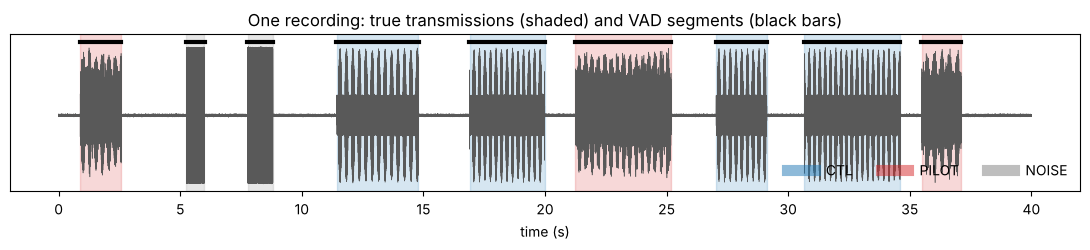

In [3]:
path = classifier.list_recordings(audio_dir)[0]
y, sr = load_audio(path)
segs = segment_vad(y, sr)
t = np.arange(len(y)) / sr
fig, ax = plt.subplots(figsize=(11, 2.6))
ax.plot(t, y, lw=0.4, color="0.35")
true_here = truth[truth["source_file"] == str(path)]
colors = {"CTL": "#1f77b4", "PILOT": "#d62728", "NOISE": "#7f7f7f"}
for _, r in true_here.iterrows():
    ax.axvspan(r["start_s"], r["end_s"], color=colors[r["label"]], alpha=0.18)
for s in segs:
    ax.plot([s.start_s, s.end_s], [0.33, 0.33], color="k", lw=3)
ax.set(xlabel="time (s)", yticks=[], title="One recording: true transmissions (shaded) and VAD segments (black bars)")
for k, c in colors.items():
    ax.plot([], [], color=c, alpha=0.5, lw=8, label=k)
ax.legend(loc="lower right", ncol=3, frameon=False)
plt.tight_layout()

## Features and labelling

Each segment is described by 36 features: 13 MFCC (mean and standard deviation), spectral centroid,
bandwidth, roll-off, zero-crossing rate, RMS, an SNR estimate and duration.

On real data, `classifier.build_annotation_set` exports every segment as a WAV file and writes a CSV
with an empty `label` column that an annotator fills after listening. Here the synthetic ground
truth stands in for that listening step.

In [4]:
segments = classifier.segment_table(classifier.list_recordings(audio_dir))
labelled = synthetic.label_by_overlap(segments, truth)
print(f"{len(segments)} segments, {(labelled['label'] == '').sum()} without a clear majority label (left out)")
labelled["label"].value_counts()

265 segments, 0 without a clear majority label (left out)


label
PILOT    119
CTL      110
NOISE     36
Name: count, dtype: int64

## Training and evaluation

A Random Forest (200 trees, depth 10) behind a standard scaler, evaluated by stratified 5-fold
cross-validation; the confusion matrix is built from out-of-fold predictions, so every labelled
segment is scored exactly once by a model that never saw it.

In [5]:
model, report = classifier.train(labelled)
print(f"Cross-validated accuracy: {report.cv_accuracy:.1%}  on {report.n_examples} segments\n")
print(report.report)
report.confusion

Cross-validated accuracy: 100.0%  on 265 segments

              precision    recall  f1-score   support

         CTL       1.00      1.00      1.00       110
       PILOT       1.00      1.00      1.00       119
       NOISE       1.00      1.00      1.00        36

    accuracy                           1.00       265
   macro avg       1.00      1.00      1.00       265
weighted avg       1.00      1.00      1.00       265



,CTL,PILOT,NOISE
CTL,110,0,0
PILOT,0,119,0
NOISE,0,0,36


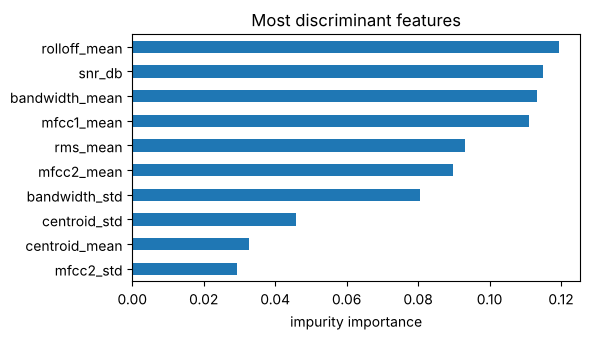

In [6]:
ax = report.top_features[::-1].plot.barh(figsize=(6, 3.5), color="#1f77b4")
ax.set(title="Most discriminant features", xlabel="impurity importance")
plt.tight_layout()

## Prediction

`classifier.predict` segments and labels every file of a folder; the confidence is the forest's
highest class probability. Downstream, only CTL and PILOT segments with confidence ≥ 0.70 are kept.

In [7]:
pred = classifier.predict_table(model, segments)
pred.head()

,segment_id,source_file,start_s,end_s,duration_s,prediction,confidence
0,rec_000_ch17_seg00,../data/synthetic_audio/rec_000_ch17.wav,0.87,2.58,1.71,PILOT,0.98
1,rec_000_ch17_seg01,../data/synthetic_audio/rec_000_ch17.wav,5.24,6.00,0.76,NOISE,1.00
2,rec_000_ch17_seg02,../data/synthetic_audio/rec_000_ch17.wav,7.76,8.81,1.05,NOISE,1.00
3,rec_000_ch17_seg03,../data/synthetic_audio/rec_000_ch17.wav,11.42,14.80,3.38,CTL,1.00
4,rec_000_ch17_seg04,../data/synthetic_audio/rec_000_ch17.wav,16.88,19.99,3.11,CTL,1.00
